### A/B Test Analysis (Marketing Campaign)

Question: Do users who see a product ad convert more than users who see a public service announcement (PSA)?

Dataset: Marketing A/B Testing (Kaggle), 588,101 users

Setup: 96% of users were shown the ad (564,577) and 4% were shown a PSA as the control group (23,524)

### Load & Overview

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Importing libraries and dataset

In [4]:
df = pd.read_csv("Marketing_AB.csv")

In [5]:
df

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...,...
588096,588096,1278437,ad,False,1,Tuesday,23
588097,588097,1327975,ad,False,1,Tuesday,23
588098,588098,1038442,ad,False,3,Tuesday,23
588099,588099,1496395,ad,False,1,Tuesday,23


In [6]:
df.info(10)

<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Unnamed: 0     588101 non-null  int64
 1   user id        588101 non-null  int64
 2   test group     588101 non-null  str  
 3   converted      588101 non-null  bool 
 4   total ads      588101 non-null  int64
 5   most ads day   588101 non-null  str  
 6   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(4), str(2)
memory usage: 27.5 MB


no empty rows in this dataset

### Cleaning

In [7]:
df.columns = df.columns.str.replace(" ", "_")

In [8]:
df

,Unnamed:_0,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...,...
588096,588096,1278437,ad,False,1,Tuesday,23
588097,588097,1327975,ad,False,1,Tuesday,23
588098,588098,1038442,ad,False,3,Tuesday,23
588099,588099,1496395,ad,False,1,Tuesday,23


In [9]:
df.columns

Index(['Unnamed:_0', 'user_id', 'test_group', 'converted', 'total_ads',
       'most_ads_day', 'most_ads_hour'],
      dtype='str')

In [10]:
df = df.drop(columns=["Unnamed:_0"])

In [11]:
df

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...
588096,1278437,ad,False,1,Tuesday,23
588097,1327975,ad,False,1,Tuesday,23
588098,1038442,ad,False,3,Tuesday,23
588099,1496395,ad,False,1,Tuesday,23


Removed spaces in columns names and removed unnecessary column "Unnamed 0"

In [12]:
df.isna().sum()

user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64

In [13]:
df["user_id"].duplicated().sum()

np.int64(0)

Dataset is already clean and doesnt contain any duplicates

In [14]:
df["converted"] = df["converted"].astype(int)

In [15]:
df.head(10)

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14
5,1137664,ad,0,734,Saturday,10
6,1116205,ad,0,264,Wednesday,13
7,1496843,ad,0,17,Sunday,18
8,1448851,ad,0,21,Tuesday,19
9,1446284,ad,0,142,Monday,14


changed values in our target column to integers (0/1)

In [16]:
df["converted"].value_counts()

converted
0    573258
1     14843
Name: count, dtype: int64

we can see that out of 588.000+ users who saw our ad => 14.843 users made a purchase

In [17]:
df["most_ads_day"].value_counts()

most_ads_day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64

What we can see from the first look that Friday is peak day, and Tuesday and Wednesday are last 

In [18]:
df["most_ads_hour"].value_counts()

most_ads_hour
13    47655
12    47298
11    46210
14    45648
15    44683
10    38939
16    37567
17    34988
18    32323
9     31004
19    30352
21    29976
20    28923
22    26432
23    20166
8     17627
7      6405
0      5536
2      5333
1      4802
3      2679
6      2068
5       765
4       722
Name: count, dtype: int64

Also from the first look, most watched hours are around afternoon (11:00-14:00), HOWEVER, doesnt mean they the most effective

In [19]:
df[df["converted"] == 1].shape[0] / df.shape[0] *100

2.523886203220195

counted conversion rate for all users => 2.5% of people who saw the ad made a purchase

In [20]:
df[(df["converted"] == 1) & (df["test_group"] == "ad")].shape[0] / df[df["test_group"] == "ad"].shape[0] * 100

2.5546559636683748

we also can see that conversion rate the group who saw an actual ad is almost the same, just a little higher => 2.55%

In [21]:
df.dtypes

user_id          int64
test_group         str
converted        int64
total_ads        int64
most_ads_day       str
most_ads_hour    int64
dtype: object

In [22]:
df.select_dtypes(include=["int64"]).describe()

,user_id,converted,total_ads,most_ads_hour
count,5.881010e+05,588101.000000,588101.000000,588101.000000
mean,1.310692e+06,0.025239,24.820876,14.469061
std,2.022260e+05,0.156850,43.715181,4.834634
min,9.000000e+05,0.000000,1.000000,0.000000
25%,1.143190e+06,0.000000,4.000000,11.000000
50%,1.313725e+06,0.000000,13.000000,14.000000
75%,1.484088e+06,0.000000,27.000000,18.000000
max,1.654483e+06,1.000000,2065.000000,23.000000


In [23]:
df["converted"] = df["converted"].astype(bool)

In [24]:
df.dtypes

user_id          int64
test_group         str
converted         bool
total_ads        int64
most_ads_day       str
most_ads_hour    int64
dtype: object

In [25]:
df.select_dtypes(include=["int64"]).describe()

,user_id,total_ads,most_ads_hour
count,5.881010e+05,588101.000000,588101.000000
mean,1.310692e+06,24.820876,14.469061
std,2.022260e+05,43.715181,4.834634
min,9.000000e+05,1.000000,0.000000
25%,1.143190e+06,4.000000,11.000000
50%,1.313725e+06,13.000000,14.000000
75%,1.484088e+06,27.000000,18.000000
max,1.654483e+06,2065.000000,23.000000


very high standard deviation, heavily right-skewed (median - 13, max - 2065)

In [26]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=day_order, ordered=True)

### EDA (Exploratory Data Analysis)

In [27]:
df2 = df

In [28]:
df["test_group"].value_counts(normalize=True)

test_group
ad     0.96
psa    0.04
Name: proportion, dtype: float64

test groups in percentages

In [29]:
group_counts = df['test_group'].value_counts()

group_share = df["test_group"].value_counts(normalize=True) *100

Text(0.5, 0, 'Ad groups')

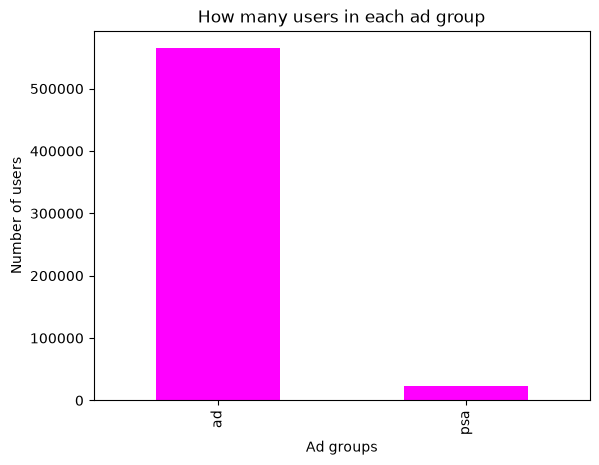

In [30]:
group_counts.plot(kind='bar', color='magenta')
plt.title('How many users in each ad group')
plt.ylabel('Number of users')
plt.xlabel('Ad groups')

Visualising shares of ad groups AD vs PSA

In [31]:
print(f"Conversion: {df['converted'].mean() *100}")

Conversion: 2.523886203220195


Average conversion

In [32]:
df.iloc[5]

user_id           1137664
test_group             ad
converted           False
total_ads             734
most_ads_day     Saturday
most_ads_hour          10
Name: 5, dtype: object

In [33]:
df.loc[5]

user_id           1137664
test_group             ad
converted           False
total_ads             734
most_ads_day     Saturday
most_ads_hour          10
Name: 5, dtype: object

In [34]:
df.loc[2:5]

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14
5,1137664,ad,False,734,Saturday,10


Text(0, 0.5, 'Number of users')

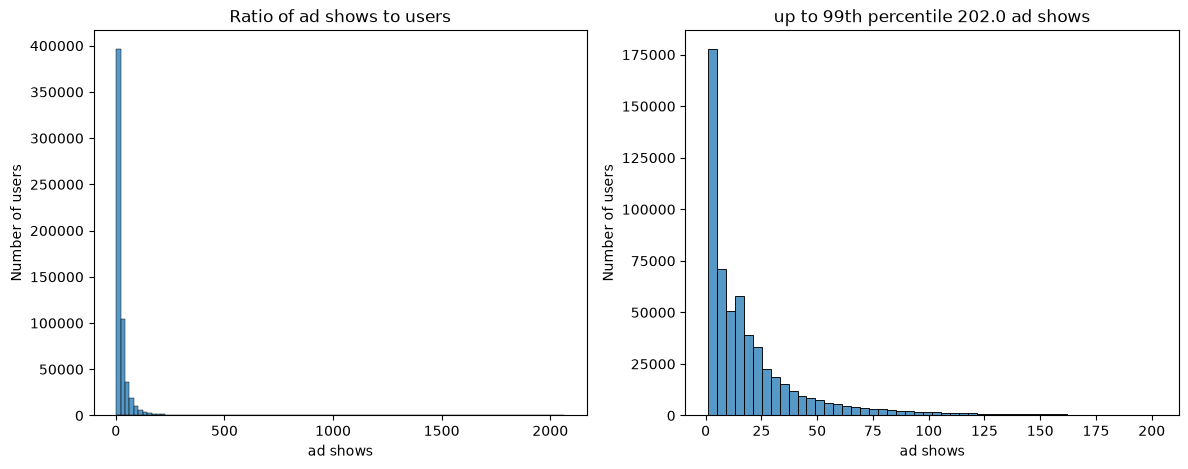

In [35]:
fig, axes = plt.subplots(1,2, figsize =(14,5))

sns.histplot(df['total_ads'], bins=100, ax=axes[0])

axes[0].set_title('Ratio of ad shows to users')
axes[0].set_xlabel('ad shows')
axes[0].set_ylabel('Number of users')

limit = df['total_ads'].quantile(0.99)

sns.histplot(df.loc[df["total_ads"] <= limit, "total_ads"], bins=50, ax=axes[1])
axes[1].set_title(f"up to 99th percentile {limit} ad shows")
axes[1].set_xlabel("ad shows")
axes[1].set_ylabel("Number of users")

In [36]:
df.groupby('test_group')['total_ads'].describe()

,count,mean,std,min,25%,50%,75%,max
test_group,,,,,,,,
ad,564577.0,24.823365,43.750456,1.0,4.0,13.0,27.0,2065.0
psa,23524.0,24.761138,42.860720,1.0,4.0,12.0,26.0,907.0


grouped by test groupes

In [37]:
day_cr = df.groupby("most_ads_day", observed=True)["converted"].mean() * 100
hour_cr = df.groupby("most_ads_hour")["converted"].mean() * 100

In [38]:
day_cr

most_ads_day
Monday       3.281155
Tuesday      2.984034
Wednesday    2.494191
Thursday     2.157094
Friday       2.221190
Saturday     2.105070
Sunday       2.447565
Name: converted, dtype: float64

In [39]:
hour_cr

most_ads_hour
0     1.842486
1     1.291129
2     0.731296
3     1.045166
4     1.523546
5     2.091503
6     2.224371
7     1.811085
8     1.951552
9     1.919107
10    2.152084
11    2.211643
12    2.382765
13    2.467737
14    2.806257
15    2.965334
16    3.077169
17    2.820967
18    2.737988
19    2.671982
20    2.980327
21    2.892314
22    2.610472
23    2.266191
Name: converted, dtype: float64

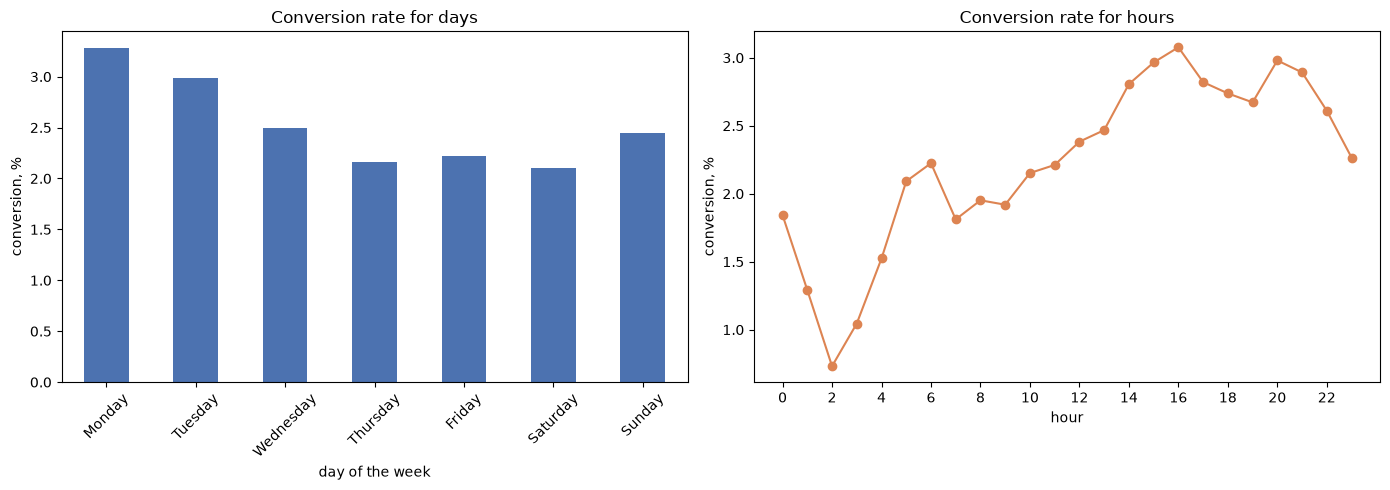

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

day_cr.plot(kind="bar", ax=axes[0], color="#4C72B0", rot=45)
axes[0].set_title("Conversion rate for days")
axes[0].set_ylabel("conversion, %")
axes[0].set_xlabel("day of the week")

hour_cr.plot(ax=axes[1], marker="o", color="#DD8452")
axes[1].set_title("Conversion rate for hours")
axes[1].set_ylabel("conversion, %")
axes[1].set_xlabel("hour")
axes[1].set_xticks(range(0, 24, 2))   # подписи по оси X через каждые 2 часа

plt.tight_layout()
plt.show()


2 graphs which demonstrate on which days and what time ads shown had the most conversions

In [42]:
bins = [0, 5, 10, 20, 50, 100, 200, np.inf]
labels = ["1–5", "6–10", "11–20", "21–50", "51–100", "101–200", "200+"]

df2["ads_bin"] = pd.cut(df["total_ads"], bins=bins, labels=labels)

In [43]:
df2

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour,ads_bin
0,1069124,ad,False,130,Monday,20,101–200
1,1119715,ad,False,93,Tuesday,22,51–100
2,1144181,ad,False,21,Tuesday,18,21–50
3,1435133,ad,False,355,Tuesday,10,200+
4,1015700,ad,False,276,Friday,14,200+
...,...,...,...,...,...,...,...
588096,1278437,ad,False,1,Tuesday,23,1–5
588097,1327975,ad,False,1,Tuesday,23,1–5
588098,1038442,ad,False,3,Tuesday,23,1–5
588099,1496395,ad,False,1,Tuesday,23,1–5


ads_bin - created a new column in which we put users into clusters (numbers of ads shown)


In [44]:
ads_cr = df.groupby("ads_bin", observed=True)["converted"].agg(["mean", "size"])
ads_cr.columns = ["conversion", "number of users"]
print(ads_cr)

         conversion  number of users
ads_bin                             
1–5        0.002525           177823
6–10       0.004931            82952
11–20      0.008393           127484
21–50      0.028859           130776
51–100     0.113952            46002
101–200    0.173679            17112
200+       0.155746             5952


most conversions happen in the group which saw ad 100-200 times 
(assumption that more ads => better conversion)

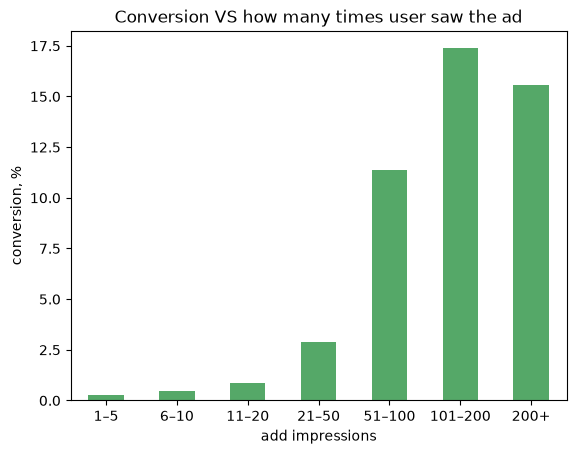

In [45]:
(ads_cr["conversion"] * 100).plot(kind="bar", rot=0, color="#55A868")
plt.title("Conversion VS how many times user saw the ad")
plt.ylabel("conversion, %")
plt.xlabel("add impressions")
plt.show()

First impresion: most conversions happen in the range of 50-200 ad shows, so more ad shows seems to be more effective
BUT bellow 200, the effect gets lost

In [46]:
corr = df2[["converted", "total_ads", "most_ads_hour"]].corr()

In [47]:
corr

,converted,total_ads,most_ads_hour
converted,1.000000,0.217419,0.019674
total_ads,0.217419,1.000000,-0.010837
most_ads_hour,0.019674,-0.010837,1.000000


corr() - shows correlation

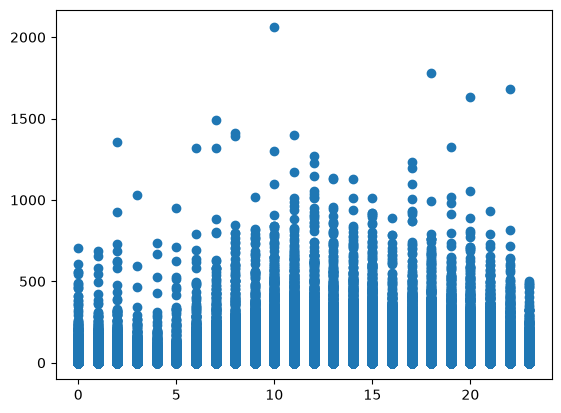

In [48]:
plt.scatter(df["most_ads_hour"], df["total_ads"])


checked correlation between most ad shows and time of the day

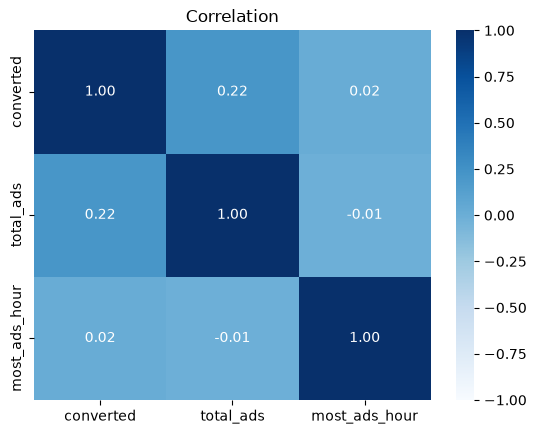

In [49]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation")
plt.show()


HEATMAP

biggest correlation between conversions and number of ads shown

### A/B Testing

In [50]:
ALPHA = 0.05

normal distribution => t-test

if not => Mann Whittney

Shapiro-Wilk Test

In [51]:
ads_ad = df.loc[df["test_group"] == "ad", "total_ads"]
ads_psa = df.loc[df["test_group"] == "psa", "total_ads"]

In [52]:
for name, values in [("ad", ads_ad), ("psa", ads_psa)]:
    sample = values.sample(5000, random_state=42)
    stat, p = stats.shapiro(sample)
    result = "normal distribution" if p > ALPHA else "not normal distribution" 
    print(f"{name}: W = {stat}, p-value = {p} -> {result}")

ad: W = 0.5145534761387706, p-value = 1.639581982074051e-79 -> not normal distribution
psa: W = 0.5214398623149031, p-value = 3.3272531913530687e-79 -> not normal distribution


Not normal distribution 
=> we cannot use t-test

Mann-Whitney U Test

In [53]:
mw_stat, mw_p = stats.mannwhitneyu(ads_ad, ads_psa, alternative="two-sided")
print(f"Mann Whitney: p_value: {mw_p}")

print(f"Mean total_ads: ad = {ads_ad.median()}, psa = {ads_psa.median()}")


Mann Whitney: p_value: 4.6909108547205694e-11
Mean total_ads: ad = 13.0, psa = 12.0


On very large samples, even a tiny difference produces a small p-value => we look not only at the p-value but also at the difference in medians. 

Here the difference is just 1 impression (13 vs 12). It is statistically significant but practically negligible: both groups saw roughly the same number of ads.

CHI SQUARE

Checking if ad shows were distributed among different ad agroups equally throughtout the week

In [54]:
day_table = pd.crosstab(df["most_ads_day"], df["test_group"])
day_table


test_group,ad,psa
most_ads_day,,
Monday,83571,3502
Tuesday,74572,2907
Wednesday,77418,3490
Thursday,79077,3905
Friday,88805,3803
Saturday,78802,2858
Sunday,82332,3059


In [55]:
chi2, chi_p, dof, _ = stats.chi2_contingency(day_table)
print(f"Chi Square for days: p-value = {chi_p:}")
print()

print("Shares of users per each day for each group, %:")
print((pd.crosstab(df["most_ads_day"], df["test_group"], normalize="columns") * 100).round(1))


Chi Square for days: p-value = 4.8490676642980583e-48

Shares of users per each day for each group, %:
test_group      ad   psa
most_ads_day            
Monday        14.8  14.9
Tuesday       13.2  12.4
Wednesday     13.7  14.8
Thursday      14.0  16.6
Friday        15.7  16.2
Saturday      14.0  12.1
Sunday        14.6  13.0


The distribution of days differs significantly between the groups (p < 0.001), although the practical difference is small: at most 2.6 p.p. (Thursday). 

For example, psa users more often saw most of their ads on Thursday, while ad users did more often on Saturday and Sunday.

-> Therefore, in the ad-hoc analysis we compare conversion between groups within each day, to rule out the effect of day of the week on the result.

In [56]:
!pip install statsmodels


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Z-TEST

In [89]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

summary = df.groupby("test_group")["converted"].agg(["sum", "count", "mean"])
summary.columns = ["sales", "users", "conversion"]
print(summary)

conv_ad, n_ad = summary.loc["ad", "sales"], summary.loc["ad", "users"]
conv_psa, n_psa = summary.loc["psa", "sales"], summary.loc["psa", "users"]

cr_ad, cr_psa = conv_ad / n_ad, conv_psa / n_psa

            sales   users  conversion
test_group                           
ad          14423  564577    0.025547
psa           420   23524    0.017854


sales, number of users and conversion rate for each group

In [58]:
z_stat, z_p = proportions_ztest(
    count=[conv_ad, conv_psa],   
    nobs=[n_ad, n_psa],          
    alternative="larger",
)

ci_low, ci_high = confint_proportions_2indep(conv_ad, n_ad, conv_psa, n_psa, compare="diff")

diff = cr_ad - cr_psa
lift = diff / cr_psa

print(f"Conversion ad:  {cr_ad:.2%}")
print(f"Conversion psa: {cr_psa:.2%}")
print(f"Difference: {diff * 100:.2f} pp (95% CI: {ci_low * 100:.2f} … {ci_high * 100:.2f} pp)")
print(f"Relative lift: {lift:.0%}")
print(f"z = {z_stat:.2f}, p-value = {z_p:.3g}")
print()

if z_p < ALPHA:
    print("p-value < 0.05: we reject H0, the ad significantly increases conversion.")
else:
    print("p-value >= 0.05: not enough reasons to reject H0.")


Conversion ad:  2.55%
Conversion psa: 1.79%
Difference: 0.77 pp (95% CI: 0.59 … 0.94 pp)
Relative lift: 43%
z = 7.37, p-value = 8.53e-14

p-value < 0.05: we reject H0, the ad significantly increases conversion.


BOOTSTRAP

In [91]:
rng = np.random.default_rng(42)

conv_ad_values = df.loc[df["test_group"] == "ad", "converted"].to_numpy()
conv_psa_values = df.loc[df["test_group"] == "psa", "converted"].to_numpy()

In [63]:
conv_ad_values

array([False, False, False, ..., False, False, False], shape=(564577,))

In [93]:
boot_diffs = []
for _ in range(1000):  
    sample_ad = rng.choice(conv_ad_values, size=len(conv_ad_values), replace=True)
    sample_psa = rng.choice(conv_psa_values, size=len(conv_psa_values), replace=True)
    boot_diffs.append(sample_ad.mean() - sample_psa.mean())

boot_diffs = np.array(boot_diffs)

In [98]:
boot_low, boot_high = np.percentile(boot_diffs, [2.5, 97.5])

share_le_zero = (boot_diffs <= 0).mean()

print(f"Bootstrap 95% CI difference: {boot_low * 100:.2f} … {boot_high * 100:.2f} pp")
print(f"Share of bootstrap difference <= 0: {share_le_zero:.1%}")

Bootstrap 95% CI difference: 0.60 … 0.93 pp
Share of bootstrap difference <= 0: 0.0%


In [70]:
boot_diffs.min()

np.float64(0.00460695235592002)

Bootstrap 95% CI: 0.60 … 0.93 pp
Share ≤ 0: 0.0%. In none of the 1000 simulations pca beats ad

boot_diffs.min() = 0.0046 → 0.46 pp. Even the worst of all 1,000 simulations still showed a positive lift

KDE (Kernel Density Estimation)

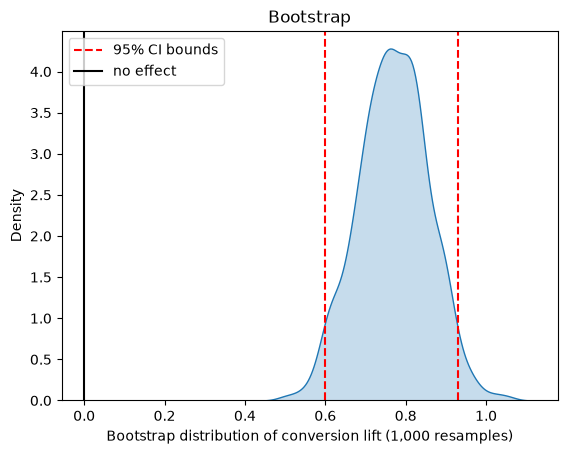

In [97]:
sns.kdeplot(boot_diffs * 100, fill=True)

plt.axvline(boot_low * 100, color="red", linestyle="--", label="95% CI bounds")
plt.axvline(boot_high * 100, color="red", linestyle="--")
plt.axvline(0, color="black", label="no effect")

plt.title("Bootstrap")
plt.xlabel("Bootstrap distribution of conversion lift (1,000 resamples)")
plt.legend()
plt.show()

Now we will check what the results (conversion) would be without the ad

In [99]:
expected_without_ads = n_ad * cr_psa

In [77]:
print(expected_without_ads)

10080.017854106443


In [76]:
print(conv_ad)

14423


In [102]:
extra_purchases = conv_ad - expected_without_ads

print(f"Number of conversions in ad group: {conv_ad:,.0f}")
print(f"Expected number of conversions without ad: {expected_without_ads:,.0f}")
print(f"Purchuases due to ads: ~{extra_purchases:,.0f}")
print(f"Share of ad-group purchases caused by ads: {extra_purchases / conv_ad:.0%}")

Number of conversions in ad group: 14,423
Expected number of conversions without ad: 10,080
Purchuases due to ads: ~4,343
Share of ad-group purchases caused by ads: 30%


#### A/B test conclusion: the ad works.

##### Conversion increased by about 43%. 
##### The ad generated ~4,343 additional purchases, around 30% of all purchases in the ad group. 

### AD HOC ANALYSIS

#### 3 main questions:

- On which days does the ad deliver the biggest lift?
- At what time of day do people buy most often?
- How many ads should be shown to one person?

#### 1) On which days does the ad deliver the biggest lift?

test_group          ad       psa   lift pp  users psa
most_ads_day                                         
Monday        0.033241  0.022559  1.068266       3502
Tuesday       0.030440  0.014448  1.599250       2907
Wednesday     0.025356  0.015759  0.959655       3490
Thursday      0.021637  0.020230  0.140666       3905
Friday        0.022465  0.016303  0.616203       3803
Saturday      0.021307  0.013996  0.731076       2858
Sunday        0.024620  0.020595  0.402487       3059


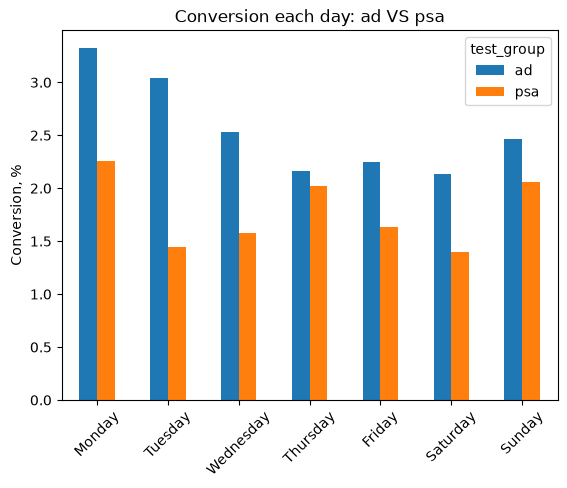

In [104]:
by_day = df.pivot_table(index="most_ads_day", columns="test_group", values="converted",
                        aggfunc="mean", observed=True)

by_day["lift pp"] = (by_day["ad"] - by_day["psa"]) * 100

by_day["users psa"] = df[df["test_group"] == "psa"].groupby("most_ads_day", observed=True).size()
print(by_day)

(by_day[["ad", "psa"]] * 100).plot(kind="bar", rot=45)
plt.title("Conversion each day: ad VS psa")
plt.ylabel("Conversion, %")
plt.xlabel("")
plt.show()

#### 2) At what time of day do people buy most often?

In [106]:
ad_only = df[df["test_group"] == "ad"]
by_hour = ad_only.groupby("most_ads_hour")["converted"].agg(["mean", "size"])

Text(0.5, 0, 'hour')

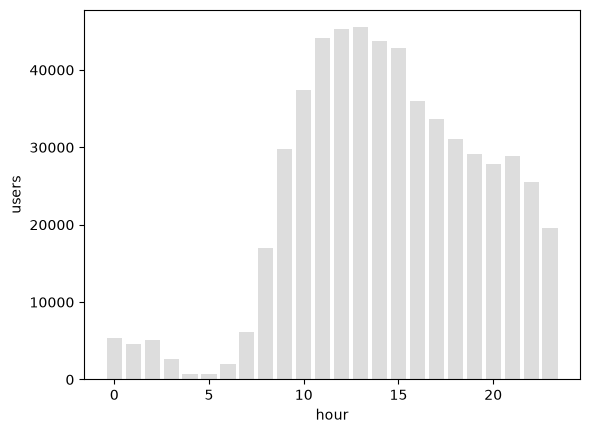

In [107]:
fig, ax1 = plt.subplots()
ax1.bar(by_hour.index, by_hour["size"], color="#DDDDDD", label="users")
ax1.set_ylabel("users")
ax1.set_xlabel("hour")

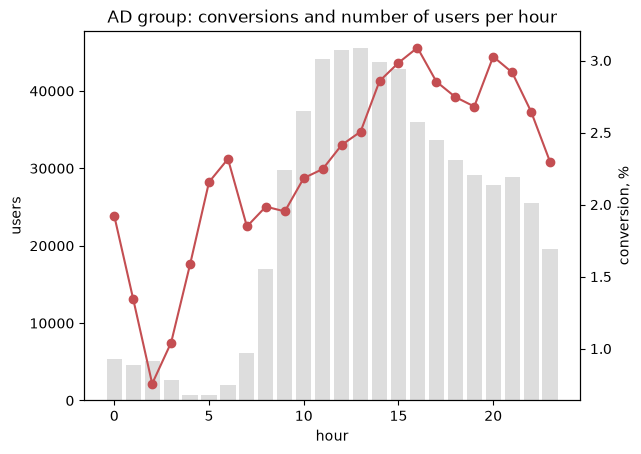

Top 5 hours with best conversion (hours with >1000 users):
                   mean   size
most_ads_hour                 
16             0.030893  35963
20             0.030274  27846
15             0.029845  42855
21             0.029175  28895
14             0.028575  43779


In [108]:
fig, ax1 = plt.subplots()
ax1.bar(by_hour.index, by_hour["size"], color="#DDDDDD", label="users")
ax1.set_ylabel("users")
ax1.set_xlabel("hour")

ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["mean"] * 100, color="#C44E52", marker="o", label="conversion")
ax2.set_ylabel("conversion, %")
plt.title("AD group: conversions and number of users per hour")
plt.show()

top_hours = by_hour[by_hour["size"] > 1000].sort_values("mean", ascending=False).head(5)
print("Top 5 hours with best conversion (hours with >1000 users):")
print(top_hours)

Best hours 14:00-16:00 and 20:00-21:00

#### 3) How many ads should be shown to one person?

In [109]:
by_freq = df.pivot_table(index="ads_bin", columns="test_group", values="converted",
                         aggfunc="mean", observed=True)

In [86]:
by_freq

test_group,ad,psa
ads_bin,,
1–5,0.002512,0.002799
6–10,0.004853,0.006735
11–20,0.008400,0.008193
21–50,0.029154,0.021777
51–100,0.116311,0.057744
101–200,0.176773,0.106383
200+,0.155778,0.155039


In [110]:
by_freq["uplift pp"] = (by_freq["ad"] - by_freq["psa"]) * 100
by_freq["users psa"] = df[df["test_group"] == "psa"].groupby("ads_bin", observed=True).size()
print(by_freq)

test_group        ad       psa  uplift pp  users psa
ads_bin                                             
1–5         0.002512  0.002799  -0.028630       7861
6–10        0.004853  0.006735  -0.188191       3415
11–20       0.008400  0.008193   0.020718       4150
21–50       0.029154  0.021777   0.737732       5235
51–100      0.116311  0.057744   5.856648       1853
101–200     0.176773  0.106383   7.038964        752
200+        0.155778  0.155039   0.073925        258


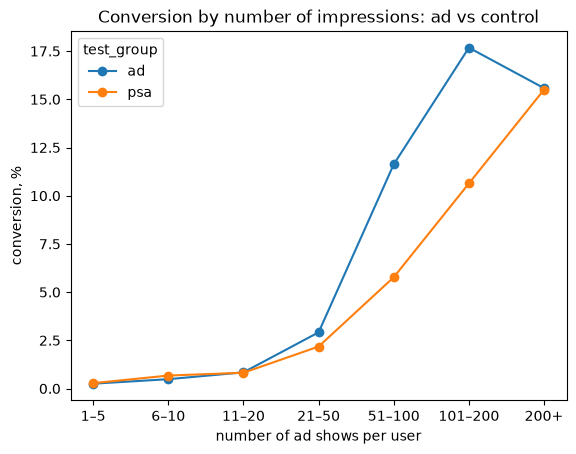

In [111]:
(by_freq[["ad", "psa"]] * 100).plot(marker="o")
plt.title("Conversion by number of impressions: ad vs control")
plt.ylabel("conversion, %")
plt.xlabel("number of ad shows per user")
plt.show()

##### Conclusion

PSA conversion also grows with impressions → active users buy more anyway. 

But at 50–200 impressions the ad has its strongest effect: ad-group conversion is 65–100% higher. 

Below 20 and above 200 impressions there’s almost no difference between groups → the optimal frequency is 50–200 impressions.